# Exp 3 — Weight divergence & sparse full vs head

- **Weight div:** dense 6×6 `td*_6_randstart` seeds 73/75
- **Full vs head (TD1–3):** sparse 6×6 `td*_6_sparse_{full,head}` seed 73
- **Full vs head (paper Orig):** sparse 6×6 `orig_6_fullgoal_{full,head}` seed 73


In [30]:
%matplotlib inline

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

CODE_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
LOG_ROOT = CODE_DIR / "hyper" / "logs"
LOG_SPARSE = CODE_DIR / "hyper" / "logs_sparse"


def load_scalars(run_dir: Path):
    ea = EventAccumulator(str(run_dir), size_guidance={"scalars": 0})
    ea.Reload()
    out = {}
    for tag in ea.Tags().get("scalars", []):
        evs = ea.Scalars(tag)
        out[tag] = pd.DataFrame(
            {"step": [e.step for e in evs], "value": [e.value for e in evs]}
        )
    return out


def load_config(run_dir: Path):
    cfg_path = run_dir / "config.json"
    if not cfg_path.exists():
        return {}
    with open(cfg_path) as f:
        return json.load(f)


def smooth(y, window=21):
    """Centered rolling mean (no zero-padding dip at the ends)."""
    y = np.asarray(y, dtype=float)
    if window is None or window <= 1 or len(y) < window:
        return y
    return pd.Series(y).rolling(window, center=True, min_periods=1).mean().to_numpy()


print("CODE_DIR:", CODE_DIR)
print("LOG_ROOT:", LOG_ROOT, "exists:", LOG_ROOT.exists())
print("LOG_SPARSE:", LOG_SPARSE, "exists:", LOG_SPARSE.exists())

CODE_DIR: /Users/maheshgondi/Documents/IITM/7/Adv_RL/hypex
LOG_ROOT: /Users/maheshgondi/Documents/IITM/7/Adv_RL/hypex/hyper/logs exists: True
LOG_SPARSE: /Users/maheshgondi/Documents/IITM/7/Adv_RL/hypex/hyper/logs_sparse exists: True


## HN weight divergence (TaskDist 1–3, both seeds)

Runs: `td{1,2,3}_6_randstart` with seeds **73** and **75** (dense Manhattan, random start, 6×6).

Metric: `hn_weight_div/mean_pairwise_l2` — mean pairwise L2 of per-goal mean actor HN weights.

Plot: mean across seeds with shaded **min–max** interval (n=2).

In [31]:
WEIGHT_DIV_TAG = "hn_weight_div/mean_pairwise_l2"
SEEDS = [73, 75]
TASK_DISTS = [1, 2, 3]


def find_randstart_run(td: int, seed: int) -> Path:
    """Latest completed td*_6_randstart run for (task dist, seed)."""
    base = LOG_ROOT / f"logs_GridNavi-TaskDist{td}-v0"
    matches = [
        d for d in base.glob(f"td{td}_6_randstart_{seed}__*")
        if d.is_dir() and list(d.glob("events.out.tfevents*"))
    ]
    if not matches:
        raise FileNotFoundError(f"No td{td}_6_randstart run for seed={seed} under {base}")
    matches.sort(
        key=lambda p: ((p / "DONE").exists(), p.stat().st_mtime),
        reverse=True,
    )
    return matches[0]


wd_curves = {}  # td -> list of DataFrames (one per seed)
for td in TASK_DISTS:
    series = []
    for seed in SEEDS:
        run = find_randstart_run(td, seed)
        sc = load_scalars(run)
        if WEIGHT_DIV_TAG not in sc:
            raise KeyError(f"{run.name}: missing {WEIGHT_DIV_TAG}")
        df = (
            sc[WEIGHT_DIV_TAG]
            .rename(columns={"value": "mean_pairwise_l2"})
            .sort_values("step")
            .reset_index(drop=True)
        )
        series.append(df)
        print(
            f"TD{td} seed={seed}: n={len(df)}  "
            f"step[{df['step'].iloc[0]}…{df['step'].iloc[-1]}]  "
            f"final D={df['mean_pairwise_l2'].iloc[-1]:.4f}  "
            f"({run.name})"
        )
    wd_curves[td] = series

TD1 seed=73: n=31  step[500…15500]  final D=3.8881  (td1_6_randstart_73__26:09_23:33:55_66dc8)
TD1 seed=75: n=31  step[500…15500]  final D=2.6673  (td1_6_randstart_75__30:09_18:04:33_7d7da)
TD2 seed=73: n=31  step[500…15500]  final D=4.3270  (td2_6_randstart_73__27:09_00:46:26_cd06d)
TD2 seed=75: n=31  step[500…15500]  final D=6.3177  (td2_6_randstart_75__30:09_19:15:52_d068a)
TD3 seed=73: n=31  step[500…15500]  final D=7.6801  (td3_6_randstart_73__27:09_01:52:53_9d7b1)
TD3 seed=75: n=31  step[500…15500]  final D=4.5016  (td3_6_randstart_75__30:09_20:20:39_d504a)


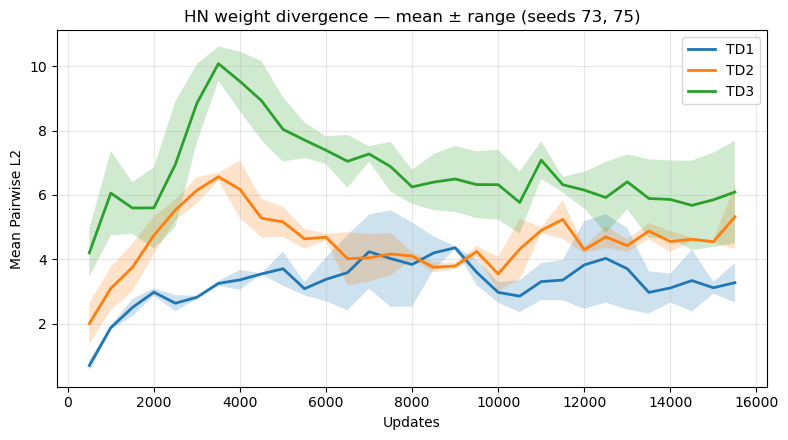

,n_seeds,final_mean,final_min,final_max,max_of_means
dist,,,,,
1,2,3.277709,2.667336,3.888082,4.362666
2,2,5.322348,4.326999,6.317696,6.565966
3,2,6.090894,4.501645,7.680144,10.074791


In [32]:
fig, ax = plt.subplots(figsize=(8, 4.5))

labels = {1: "TD1", 2: "TD2", 3: "TD3"}
wd_summary = []

for td, series in wd_curves.items():
    # Align on the intersection of logged steps across seeds
    step_sets = [set(s["step"].tolist()) for s in series]
    steps = np.array(sorted(set.intersection(*step_sets)), dtype=int)
    vals = np.stack(
        [
            s.set_index("step").loc[steps, "mean_pairwise_l2"].to_numpy(dtype=float)
            for s in series
        ],
        axis=0,
    )
    mean = vals.mean(axis=0)
    lo = vals.min(axis=0)
    hi = vals.max(axis=0)

    ax.plot(steps, mean, label=labels[td], linewidth=2)
    ax.fill_between(steps, lo, hi, alpha=0.22)

    wd_summary.append(
        {
            "dist": td,
            "n_seeds": vals.shape[0],
            "final_mean": float(mean[-1]),
            "final_min": float(lo[-1]),
            "final_max": float(hi[-1]),
            "max_of_means": float(mean.max()),
        }
    )

ax.set_xlabel("Updates")
ax.set_ylabel("Mean Pairwise L2")
ax.set_title("HN weight divergence — mean ± range (seeds 73, 75)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

pd.DataFrame(wd_summary).set_index("dist")

## Sparse full vs head (`logs_sparse`, TaskDist 1–3)

6×6 sparse (`+1` / `-0.1`), random start, seed 73.

- **Full:** `td{N}_6_sparse_full` — `policy_layers_hyper 1 1 1`
- **Head:** `td{N}_6_sparse_head` — `policy_layers_hyper 0 0 1`

In [33]:
META_TAG = "Meta-Episode Return"
SPARSE_SMOOTH = 5  # TB eval points are already sparse (~every 500 updates)
# Stop before late-training eval noise / last-checkpoint wobble.
PLOT_MAX_FRAMES = 12_000_000


def find_sparse_run(td: int, scope: str) -> Path:
    """Latest completed run for td{N}_6_sparse_{full|head}."""
    assert scope in ("full", "head")
    base = LOG_SPARSE / f"logs_GridNavi-TaskDist{td}-v0"
    label_prefix = f"td{td}_6_sparse_{scope}_"
    matches = [
        d for d in base.glob(f"{label_prefix}*")
        if d.is_dir() and list(d.glob("events.out.tfevents*"))
    ]
    if not matches:
        raise FileNotFoundError(f"No {label_prefix}* under {base}")
    matches.sort(
        key=lambda p: ((p / "DONE").exists(), p.stat().st_mtime),
        reverse=True,
    )
    return matches[0]


sparse_runs = {}
for td in (1, 2, 3):
    sparse_runs[td] = {}
    for scope in ("full", "head"):
        run = find_sparse_run(td, scope)
        sc = load_scalars(run)
        cfg = load_config(run)
        if META_TAG not in sc:
            raise KeyError(f"{run.name}: missing {META_TAG}")
        sparse_runs[td][scope] = {
            "run": run,
            "scalars": sc,
            "cfg": cfg,
            "meta": sc[META_TAG].sort_values("step").reset_index(drop=True),
        }
        df = sparse_runs[td][scope]["meta"]
        print(
            f"TD{td} {scope:4s}: n={len(df)}  "
            f"final={df['value'].iloc[-1]:.2f}  max={df['value'].max():.2f}  "
            f"DONE={(run / 'DONE').exists()}  ({run.name})"
        )


TD1 full: n=32  final=63.23  max=65.01  DONE=True  (td1_6_sparse_full_73__03:10_14:02:46_c6534)
TD1 head: n=32  final=64.74  max=65.77  DONE=True  (td1_6_sparse_head_73__03:10_15:06:34_6646c)
TD2 full: n=32  final=59.10  max=65.01  DONE=True  (td2_6_sparse_full_73__03:10_16:05:04_1befc)
TD2 head: n=32  final=62.68  max=65.70  DONE=True  (td2_6_sparse_head_73__03:10_17:12:30_98603)
TD3 full: n=32  final=55.59  max=59.86  DONE=True  (td3_6_sparse_full_73__03:10_18:09:40_55979)
TD3 head: n=32  final=59.38  max=59.58  DONE=True  (td3_6_sparse_head_73__03:10_19:19:52_b2a4)


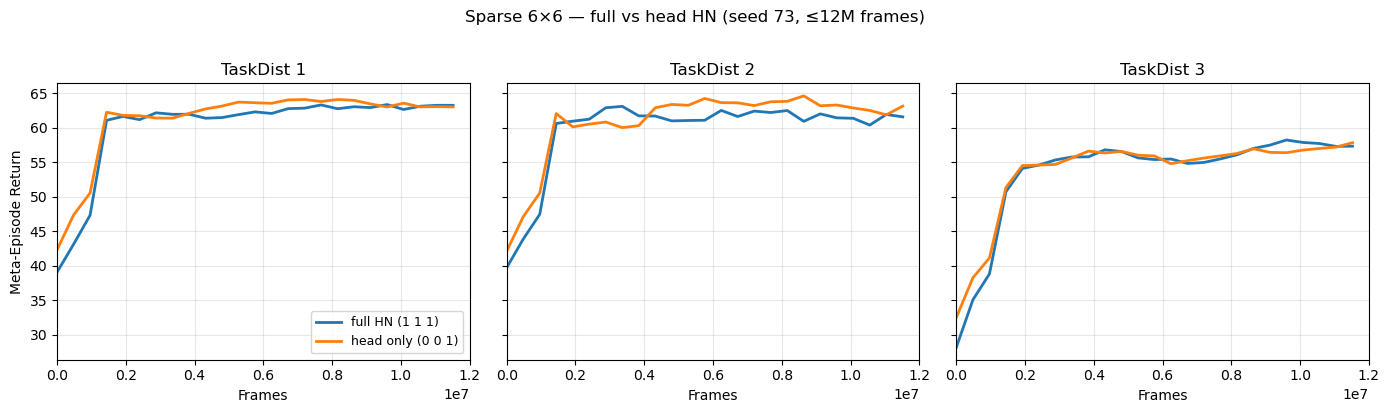

at_cutoff        max   n
dist scope                          
1    full   64.600006  65.012497  25
     head   61.437500  65.768753  25
2    full   59.581245  64.806252  25
     head   63.706253  65.699997  25
3    full   56.831249  59.581249  25
     head   59.581245  59.581245  25

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

scope_style = {
    "full": {"color": "C0", "label": "full HN (1 1 1)"},
    "head": {"color": "C1", "label": "head only (0 0 1)"},
}

rows = []
for ax, td in zip(axes, (1, 2, 3)):
    for scope, style in scope_style.items():
        df = sparse_runs[td][scope]["meta"]
        df = df[df["step"] <= PLOT_MAX_FRAMES]
        y = smooth(df["value"], SPARSE_SMOOTH)
        ax.plot(df["step"], y, color=style["color"], linewidth=2, label=style["label"])
        rows.append(
            {
                "dist": td,
                "scope": scope,
                "at_cutoff": float(df["value"].iloc[-1]),
                "max": float(df["value"].max()),
                "n": len(df),
            }
        )
    ax.set_title(f"TaskDist {td}")
    ax.set_xlabel("Frames")
    ax.set_xlim(0, PLOT_MAX_FRAMES)
    ax.grid(True, alpha=0.3)
    if td == 1:
        ax.set_ylabel("Meta-Episode Return")
        ax.legend(loc="lower right", fontsize=9)

fig.suptitle(
    f"Sparse 6×6 — full vs head HN (seed 73, ≤{PLOT_MAX_FRAMES/1e6:.0f}M frames)",
    y=1.02,
)
fig.tight_layout()
plt.show()

pd.DataFrame(rows).set_index(["dist", "scope"])

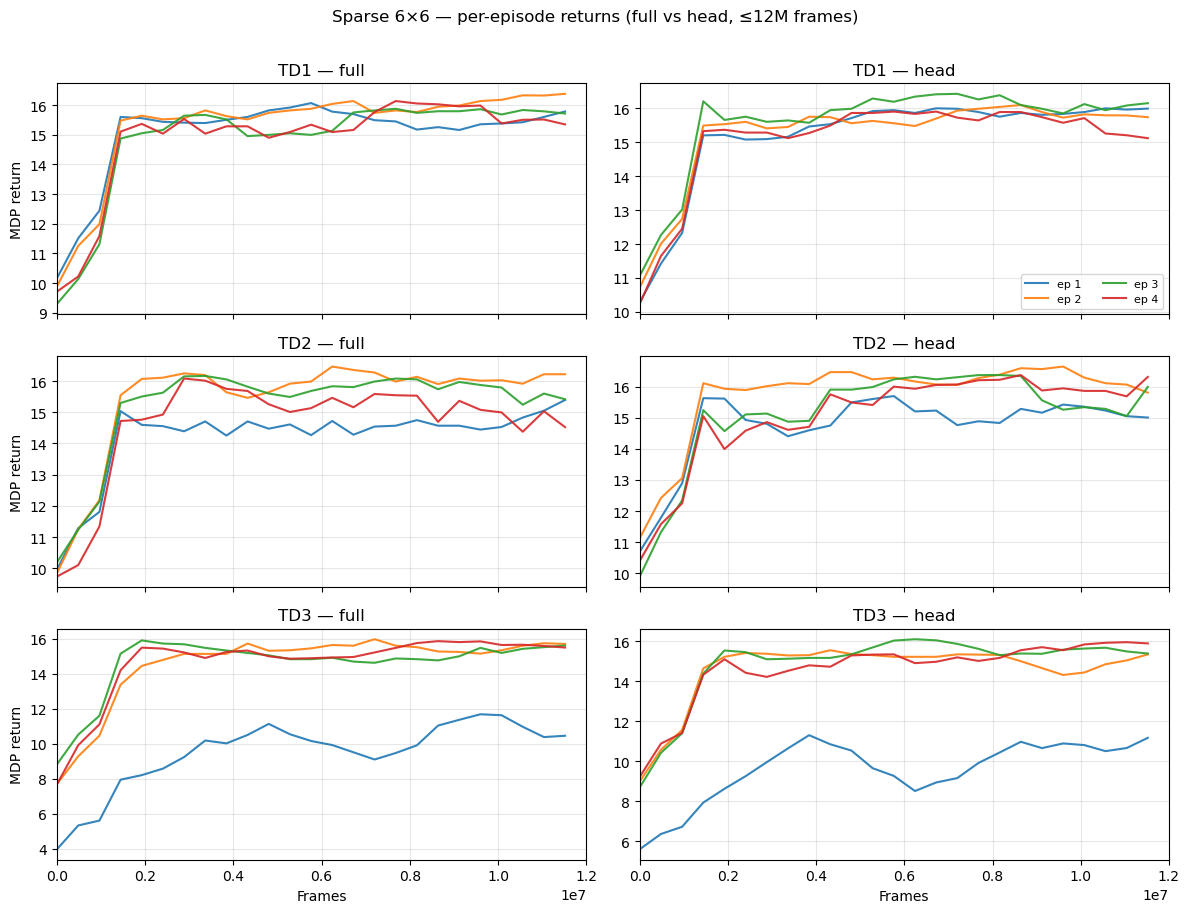

In [35]:
# Per-MDP-episode returns (episodes 1–4) for each TaskDist
K_SPARSE = 4
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)

for row, td in enumerate((1, 2, 3)):
    for col, scope in enumerate(("full", "head")):
        ax = axes[row, col]
        sc = sparse_runs[td][scope]["scalars"]
        for k in range(1, K_SPARSE + 1):
            tag = f"return_avg_per_frame/episode_{k}"
            if tag not in sc:
                continue
            df = sc[tag].sort_values("step")
            df = df[df["step"] <= PLOT_MAX_FRAMES]
            ax.plot(df["step"], smooth(df["value"], SPARSE_SMOOTH), label=f"ep {k}", alpha=0.9)
        ax.set_title(f"TD{td} — {scope}")
        ax.set_xlim(0, PLOT_MAX_FRAMES)
        ax.grid(True, alpha=0.3)
        if row == 2:
            ax.set_xlabel("Frames")
        if col == 0:
            ax.set_ylabel("MDP return")
        if row == 0 and col == 1:
            ax.legend(fontsize=8, ncol=2)

fig.suptitle(
    f"Sparse 6×6 — per-episode returns (full vs head, ≤{PLOT_MAX_FRAMES/1e6:.0f}M frames)",
    y=1.01,
)
fig.tight_layout()
plt.show()

## Sparse full vs head — paper Orig (`GridNavi-Orig-v0`)

6×6 sparse, **fixed start `(0,0)`**, goals ≈ all cells except the start neighborhood (paper-style support).

- **Full:** `orig_6_fullgoal_full` — `1 1 1`
- **Head:** `orig_6_fullgoal_head` — `0 0 1`

Same seed 73 / budget as the TaskDist sparse runs; plots use the same `PLOT_MAX_FRAMES` cutoff.

In [36]:
def find_orig_run(scope: str) -> Path:
    """Latest completed orig_6_fullgoal_{full|head} run."""
    assert scope in ("full", "head")
    base = LOG_SPARSE / "logs_GridNavi-Orig-v0"
    label_prefix = f"orig_6_fullgoal_{scope}_"
    matches = [
        d for d in base.glob(f"{label_prefix}*")
        if d.is_dir() and list(d.glob("events.out.tfevents*"))
    ]
    if not matches:
        raise FileNotFoundError(f"No {label_prefix}* under {base}")
    matches.sort(
        key=lambda p: ((p / "DONE").exists(), p.stat().st_mtime),
        reverse=True,
    )
    return matches[0]


orig_runs = {}
for scope in ("full", "head"):
    run = find_orig_run(scope)
    sc = load_scalars(run)
    if META_TAG not in sc:
        raise KeyError(f"{run.name}: missing {META_TAG}")
    orig_runs[scope] = {
        "run": run,
        "scalars": sc,
        "meta": sc[META_TAG].sort_values("step").reset_index(drop=True),
    }
    df = orig_runs[scope]["meta"]
    print(
        f"Orig {scope:4s}: n={len(df)}  "
        f"final={df['value'].iloc[-1]:.2f}  max={df['value'].max():.2f}  "
        f"DONE={(run / 'DONE').exists()}  ({run.name})"
    )

Orig full: n=32  final=33.59  max=48.17  DONE=True  (orig_6_fullgoal_full_73__06:10_18:58:07_c21a7)
Orig head: n=32  final=40.54  max=52.43  DONE=True  (orig_6_fullgoal_head_73__06:10_20:06:21_93fca)


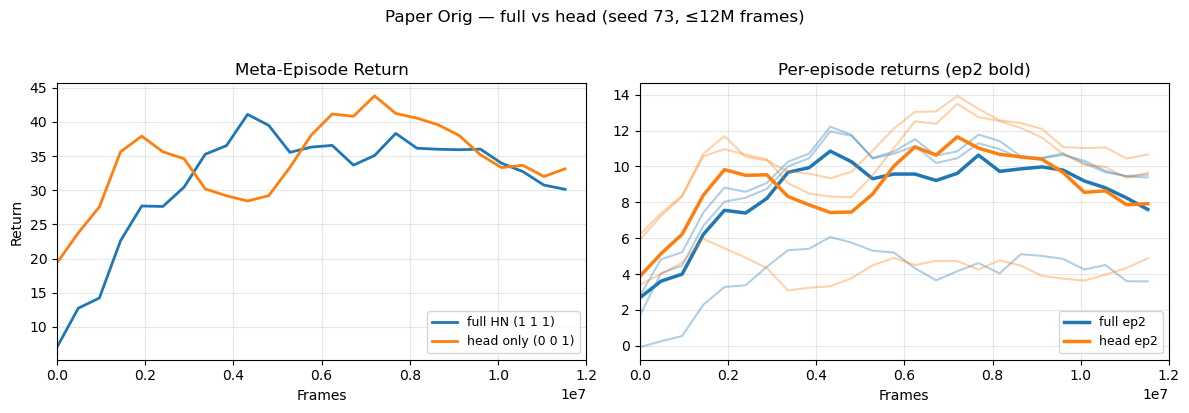

,at_cutoff,max,n
scope,,,
full,31.256252,48.168747,25
head,42.531250,52.431252,25


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

scope_style = {
    "full": {"color": "C0", "label": "full HN (1 1 1)"},
    "head": {"color": "C1", "label": "head only (0 0 1)"},
}

# Meta-Episode Return
ax = axes[0]
rows = []
for scope, style in scope_style.items():
    df = orig_runs[scope]["meta"]
    df = df[df["step"] <= PLOT_MAX_FRAMES]
    ax.plot(
        df["step"],
        smooth(df["value"], SPARSE_SMOOTH),
        color=style["color"],
        linewidth=2,
        label=style["label"],
    )
    rows.append(
        {
            "scope": scope,
            "at_cutoff": float(df["value"].iloc[-1]),
            "max": float(df["value"].max()),
            "n": len(df),
        }
    )
ax.set_title("Meta-Episode Return")
ax.set_xlabel("Frames")
ax.set_ylabel("Return")
ax.set_xlim(0, PLOT_MAX_FRAMES)
ax.legend(loc="lower right", fontsize=9)
ax.grid(True, alpha=0.3)

# Per-episode returns, full vs head overlaid for episode 2 (adaptation) and all eps lightly
ax = axes[1]
for scope, style in scope_style.items():
    sc = orig_runs[scope]["scalars"]
    for k in range(1, 5):
        tag = f"return_avg_per_frame/episode_{k}"
        if tag not in sc:
            continue
        df = sc[tag].sort_values("step")
        df = df[df["step"] <= PLOT_MAX_FRAMES]
        ax.plot(
            df["step"],
            smooth(df["value"], SPARSE_SMOOTH),
            color=style["color"],
            alpha=0.35 if k != 2 else 1.0,
            linewidth=1.5 if k != 2 else 2.5,
            label=f"{scope} ep{k}" if k == 2 else None,
        )
ax.set_title("Per-episode returns (ep2 bold)")
ax.set_xlabel("Frames")
ax.set_xlim(0, PLOT_MAX_FRAMES)
ax.legend(loc="lower right", fontsize=9)
ax.grid(True, alpha=0.3)

fig.suptitle(
    f"Paper Orig — full vs head (seed 73, ≤{PLOT_MAX_FRAMES/1e6:.0f}M frames)",
    y=1.02,
)
fig.tight_layout()
plt.show()

pd.DataFrame(rows).set_index("scope")